# 02 — Kat-İçi Ön İşleme, Manuel/Otomatik HP Araması ve 3×3 Nested CV

Bu notebook yalnızca **development** verisini kullanır. Test kümesi okunmaz.
Adaylar (M1–M6, R1–R6) bu notebook çalıştırılmadan önce `configs/` altında sabitlenip commit edilmiştir.
Outer değerlendirme skorları hiçbir seçimde kullanılmaz; nihai seçim tüm development üzerindeki iç CV ile yapılır.

## 0. Kurulum

In [1]:
# Google Colab'da çalıştırılıyorsa aşağıdaki iki satırın başındaki '#' kaldırılır:
# !git clone https://github.com/mesutissever/ysa-midterm-mlp-nested-cv.git
# %cd ysa-midterm-mlp-nested-cv
# (Ham veri: data/bank-additional.csv — README'deki indirme talimatına bakınız)

In [2]:
import sys, os, json, platform
sys.path.insert(0, os.path.abspath("."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, sklearn

from src.data import load_seeds, get_dev_test, TARGET
from src.configs import load_candidates, load_json
from src.preprocessing import _leak_check
from src.model import expected_params
from src.nested_cv import run_nested_cv, METRIC_COLS

pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
FIG, RES = "figures", "results"
def savefig(name): plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")

seeds = load_seeds()
df_dev, _ = get_dev_test()          # test kümesi kullanılmıyor
cands = load_candidates()
print("Development:", df_dev.shape, "| pozitif oranı:", round(df_dev[TARGET].mean(), 4))
print(f"Python {platform.python_version()} | torch {torch.__version__} | sklearn {sklearn.__version__} | "
      f"{platform.platform()} | {platform.processor()} | CUDA: {torch.cuda.is_available()}")
print("Seeds:", seeds)

Development: (3295, 20) | pozitif oranı: 0.1096
Python 3.13.1 | torch 2.15.0+cpu | sklearn 1.9.1 | Windows-11-10.0.26200-SP0 | Intel64 Family 6 Model 151 Stepping 2, GenuineIntel | CUDA: False
Seeds: {'student_last5': 29015, 'base_seed': 31041, 'derivation': 'base_seed + offset', 'split': 31041, 'outer_cv': 31042, 'inner_cv': 31043, 'early_stop_split': 31044, 'random_search': 31045, 'torch_init': 31046, 'final_seeds': [31046, 31146, 31246], 'bootstrap': 31047}


## 1. Kat-içi ön işleme: sızıntı kontrolü

In [3]:
_leak_check()

scaler=standard clip=False -> boyut fit=(2306, 60), other=(989, 60)
scaler=standard clip=True  -> boyut fit=(2306, 60), other=(989, 60)
scaler=minmax   clip=False -> boyut fit=(2306, 60), other=(989, 60)
scaler=minmax   clip=True  -> boyut fit=(2306, 60), other=(989, 60)
scaler=robust   clip=False -> boyut fit=(2306, 60), other=(989, 60)
scaler=robust   clip=True  -> boyut fit=(2306, 60), other=(989, 60)
OK: StandardScaler istatistikleri yalnızca fit alt kümesinden öğrenildi.
OK: Kırpma eşikleri fit alt kümesinden öğrenildi; pdays kırpılmıyor.
    Eşikler: {'age': (np.float64(24.0), np.float64(70.9)), 'campaign': (np.float64(1.0), np.float64(14.0)), 'previous': (np.float64(0.0), np.float64(2.0)), 'emp.var.rate': (np.float64(-3.4), np.float64(1.4)), 'cons.price.idx': (np.float64(92.201), np.float64(94.601)), 'cons.conf.idx': (np.float64(-50.0), np.float64(-26.9)), 'euribor3m': (np.float64(0.683), np.float64(4.968)), 'nr.employed': (np.float64(4963.6), np.float64(5228.1))}
OK: Görülmemiş

## 2. Sabitlenmiş adaylar ve eğitim ayarları

In [4]:
training = load_json("training.json")
print(json.dumps(training, ensure_ascii=False, indent=1))
cand_tbl = pd.DataFrame([*cands["manual"].values(), *cands["random"].values()]).set_index("code")
cand_tbl["hidden"] = cand_tbl["hidden"].apply(lambda h: str(tuple(h)))
cand_tbl["params (d=61)"] = [expected_params(61, eval(h)) for h in cand_tbl["hidden"]]
cand_tbl.drop(columns="purpose").fillna("")

{
 "max_epochs": 150,
 "early_stopping": {
  "patience": 15,
  "restore_best_weights": true,
  "min_delta": 0.0,
  "monitor": "internal validation BCE loss (mode=min)",
  "monitor_fraction": 0.15,
  "monitor_split": "stratified"
 },
 "lr_scheduler": {
  "name": "ReduceLROnPlateau",
  "mode": "min",
  "factor": 0.5,
  "patience": 5,
  "min_lr": 1e-05
 },
 "sgd_momentum": 0.9,
 "loss": "BCEWithLogitsLoss",
 "output": "single logit + sigmoid",
 "outer_cv": {
  "name": "StratifiedKFold",
  "n_splits": 3,
  "shuffle": true
 },
 "inner_cv": {
  "name": "StratifiedKFold",
  "n_splits": 3,
  "shuffle": true
 },
 "selection_metric": "average_precision_score (AP), inner CV mean",
 "threshold": 0.5,
 "class_weight": null,
 "device": "cpu"
}


,optimizer,hidden,activation,lr,weight_decay,batch_size,scaler,dropout,clip,scheduler,params (d=61)
code,,,,,,,,,,,
M1,adamw,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,True,2017
M2,adam,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,True,2017
M3,sgd,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,True,2017
M4,adamw,"(32,)",relu,0.001000,0.00010,64,minmax,0.0,False,True,2017
M5,adamw,"(64, 32)",relu,0.001000,0.00010,64,standard,0.0,False,True,6081
M6,adamw,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,False,2017
R1,sgd,"(16,)",relu,0.027370,0.00001,64,minmax,0.2,False,True,1009
R2,sgd,"(32,)",relu,0.005750,0.00001,128,minmax,0.0,True,True,2017
R3,adam,"(64,)",tanh,0.000459,0.00010,64,minmax,0.0,False,True,4033


## 3. Nested CV'nin çalıştırılması

- Outer `StratifiedKFold(3, shuffle=True, random_state=31042)`, inner `StratifiedKFold(3, shuffle=True, random_state=31043)`.
- Her eğitimde: %85 fit (ön işleme fit + ağırlıklar) / %15 early-stop (BCE, scheduler) — seed 31044; ağırlık seed'i 31046.
- Bütçe: 3×3×12 = 108 iç eğitim + 6 refit + 36 development seçim eğitimi = **150 MLP eğitimi**.

`RUN = True` ise deney baştan çalıştırılır ve `results/` altına yazılır (CPU'da yaklaşık 5–10 dk).
`RUN = False` ise kayıtlı sonuçlar okunur.

In [5]:
RUN = True
if RUN:
    out = run_nested_cv(df_dev, cands, seeds, save=True, verbose=True)


=== DIŞ KAT 1: outer-train=2196, outer-eval=1099 ===
  {'outer_fold': 1} M1: mean AP=0.4625 (son kat best_ep=6, uyarı yok)
  {'outer_fold': 1} M2: mean AP=0.4610 (son kat best_ep=6, uyarı yok)
  {'outer_fold': 1} M3: mean AP=0.4476 (son kat best_ep=38, uyarı yok)
  {'outer_fold': 1} M4: mean AP=0.4446 (son kat best_ep=11, uyarı yok)
  {'outer_fold': 1} M5: mean AP=0.4676 (son kat best_ep=8, uyarı yok)
  {'outer_fold': 1} M6: mean AP=0.4625 (son kat best_ep=6, uyarı yok)
  {'outer_fold': 1} R1: mean AP=0.4385 (son kat best_ep=5, uyarı yok)
  {'outer_fold': 1} R2: mean AP=0.4298 (son kat best_ep=38, uyarı yok)
  {'outer_fold': 1} R3: mean AP=0.4541 (son kat best_ep=16, uyarı yok)
  {'outer_fold': 1} R4: mean AP=0.4282 (son kat best_ep=12, uyarı yok)
  {'outer_fold': 1} R5: mean AP=0.4178 (son kat best_ep=8, uyarı yok)
  {'outer_fold': 1} R6: mean AP=0.4664 (son kat best_ep=18, uyarı yok)
  Seçilen: manuel=M5, otomatik=R6

=== DIŞ KAT 2: outer-train=2197, outer-eval=1098 ===
  {'outer_fo

## 4. Sonuçların okunması

In [6]:
inner  = pd.read_csv(f"{RES}/inner_cv_results.csv", keep_default_na=False)
manual = pd.read_csv(f"{RES}/manual_search_results.csv")
rand   = pd.read_csv(f"{RES}/random_search_results.csv")
outer  = pd.read_csv(f"{RES}/outer_cv_results.csv", keep_default_na=False)
summ   = pd.read_csv(f"{RES}/outer_cv_summary_formatted.csv", index_col=0)
sel    = pd.read_csv(f"{RES}/outer_selections.csv")
hist   = pd.read_csv(f"{RES}/training_histories.csv")
dev_sel = json.load(open(f"{RES}/dev_selection.json", encoding="utf-8"))
print("İç eğitim sayısı:", len(inner), "| toplam süre (dk):", round(dev_sel["total_runtime_s"] / 60, 1))

İç eğitim sayısı: 144 | toplam süre (dk): 2.9


### Tablo 4b — Manuel adaylar (M1–M6): iç CV mean AP ± SD, süre, en iyi epoch

In [7]:
cols = ["scope", "code", "mean_AP", "sd_AP", "mean_ROC_AUC", "mean_time_s", "mean_best_epoch",
        "mean_stopped_epoch", "n_params", "n_warnings", "optimizer", "hidden", "scaler", "lr", "scheduler"]
manual[cols].round(4)

,scope,code,mean_AP,sd_AP,mean_ROC_AUC,mean_time_s,mean_best_epoch,mean_stopped_epoch,n_params,n_warnings,optimizer,hidden,scaler,lr,scheduler
0,development,M1,0.4394,0.0456,0.7751,1.0617,19.6667,34.6667,2006.3333,0,adamw,"(32,)",standard,0.001,True
1,development,M2,0.4408,0.0456,0.7753,1.0132,19.6667,34.6667,2006.3333,0,adam,"(32,)",standard,0.001,True
2,development,M3,0.4318,0.0413,0.7788,2.9481,128.0000,136.6667,2006.3333,2,sgd,"(32,)",standard,0.001,True
3,development,M4,0.4312,0.0370,0.7675,1.1845,25.6667,40.6667,2006.3333,0,adamw,"(32,)",minmax,0.001,True
4,development,M5,0.4301,0.0406,0.7660,1.1475,12.6667,27.6667,6059.6667,0,adamw,"(64, 32)",standard,0.001,True
5,development,M6,0.4394,0.0456,0.7751,1.0819,19.6667,34.6667,2006.3333,0,adamw,"(32,)",standard,0.001,False
6,outer_1,M1,0.4625,0.0098,0.7868,1.3961,9.3333,24.3333,1985.0000,0,adamw,"(32,)",standard,0.001,True
7,outer_1,M2,0.4610,0.0125,0.7861,0.5240,8.6667,23.6667,1985.0000,0,adam,"(32,)",standard,0.001,True
8,outer_1,M3,0.4476,0.0138,0.7832,1.3394,75.6667,87.0000,1985.0000,1,sgd,"(32,)",standard,0.001,True
9,outer_1,M4,0.4446,0.0209,0.7862,0.5978,13.3333,28.3333,1985.0000,0,adamw,"(32,)",minmax,0.001,True


### Tablo 5c — Otomatik adaylar (R1–R6): iç CV mean AP ± SD, süre, en iyi epoch

In [8]:
cols_r = cols[:10] + ["optimizer", "hidden", "activation", "lr", "weight_decay", "batch_size", "scaler", "dropout", "clip"]
rand[cols_r].round(4)

,scope,code,mean_AP,sd_AP,mean_ROC_AUC,mean_time_s,mean_best_epoch,mean_stopped_epoch,n_params,n_warnings,optimizer,hidden,activation,lr,weight_decay,batch_size,scaler,dropout,clip
0,development,R1,0.4264,0.0558,0.7728,0.8262,17.6667,32.6667,1003.6667,0,sgd,"(16,)",relu,0.0274,0.0000,64,minmax,0.2,False
1,development,R2,0.4299,0.0337,0.7761,1.4689,107.0000,118.3333,2006.3333,1,sgd,"(32,)",relu,0.0058,0.0000,128,minmax,0.0,True
2,development,R3,0.4228,0.0334,0.7663,1.8520,46.6667,61.6667,4011.6667,0,adam,"(64,)",tanh,0.0005,0.0001,64,minmax,0.0,False
3,development,R4,0.4353,0.0497,0.7785,3.0510,38.3333,53.3333,1003.6667,0,adam,"(16,)",relu,0.0008,0.0010,32,robust,0.2,True
4,development,R5,0.4074,0.0349,0.7742,0.6667,17.6667,32.6667,4011.6667,0,adamw,"(64,)",relu,0.0019,0.0000,128,robust,0.2,True
5,development,R6,0.4288,0.0402,0.7732,2.1482,47.0000,62.0000,4011.6667,0,adamw,"(64,)",tanh,0.0002,0.0000,64,standard,0.2,True
6,outer_1,R1,0.4385,0.0354,0.7850,0.5400,15.3333,30.3333,993.0000,0,sgd,"(16,)",relu,0.0274,0.0000,64,minmax,0.2,False
7,outer_1,R2,0.4298,0.0147,0.7874,0.7917,80.0000,90.0000,1985.0000,1,sgd,"(32,)",relu,0.0058,0.0000,128,minmax,0.0,True
8,outer_1,R3,0.4541,0.0235,0.7834,0.7967,21.3333,36.3333,3969.0000,0,adam,"(64,)",tanh,0.0005,0.0001,64,minmax,0.0,False
9,outer_1,R4,0.4282,0.0345,0.7888,1.5399,23.0000,38.0000,993.0000,0,adam,"(16,)",relu,0.0008,0.0010,32,robust,0.2,True


### Her dış katta seçilen adaylar

In [9]:
sel

,outer_fold,manual_search,random_search
0,1,M5,R6
1,2,M3,R6
2,3,M2,R2


### Tablo 6 — Dış kat bazlı sonuçlar (manuel, otomatik, referans modeller)

In [10]:
outer[["outer_fold", "method", "selected"] + METRIC_COLS + ["TP", "FP", "TN", "FN", "train_time_s"]].round(4)

,outer_fold,method,selected,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy,TP,FP,TN,FN,train_time_s
0,1,manual_search,M5,0.3666,0.7500,0.8854,0.4510,0.1901,0.9714,0.2674,0.5807,23,28,950,98,0.8533
1,1,random_search,R6,0.3739,0.7485,0.8917,0.5217,0.1983,0.9775,0.2874,0.5879,24,22,956,97,2.3905
2,1,dummy,dummy,0.1101,0.5000,0.8899,0.0000,0.0000,1.0000,0.0000,0.5000,0,0,978,121,0.0008
3,1,logreg,logreg,0.3915,0.7587,0.8944,0.5472,0.2397,0.9755,0.3333,0.6076,29,24,954,92,0.0834
4,2,manual_search,M3,0.4554,0.7918,0.9026,0.6757,0.2083,0.9877,0.3185,0.5980,25,12,966,95,3.2389
5,2,random_search,R6,0.4500,0.7810,0.9071,0.6957,0.2667,0.9857,0.3855,0.6262,32,14,964,88,3.3590
6,2,dummy,dummy,0.1093,0.5000,0.8907,0.0000,0.0000,1.0000,0.0000,0.5000,0,0,978,120,0.0008
7,2,logreg,logreg,0.4478,0.7745,0.9117,0.7447,0.2917,0.9877,0.4192,0.6397,35,12,966,85,0.0840
8,3,manual_search,M2,0.4659,0.7987,0.9044,0.6829,0.2333,0.9867,0.3478,0.6100,28,13,965,92,0.9193
9,3,random_search,R2,0.4290,0.7888,0.9016,0.6429,0.2250,0.9847,0.3333,0.6048,27,15,963,93,1.7446


### Tablo 7 — Dış CV Mean ± SD (n = 3, örnek SD)

In [11]:
summ[["AP", "ROC_AUC", "F1", "Sensitivity", "Specificity", "Balanced_Accuracy", "Precision", "Accuracy", "train_time_s"]]

,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy,Precision,Accuracy,train_time_s
method,,,,,,,,,
manual_search,0.429 ± 0.055,0.780 ± 0.026,0.311 ± 0.041,0.211 ± 0.022,0.982 ± 0.009,0.596 ± 0.015,0.603 ± 0.132,0.897 ± 0.010,1.671 ± 1.359
random_search,0.418 ± 0.039,0.773 ± 0.021,0.335 ± 0.049,0.230 ± 0.034,0.983 ± 0.004,0.606 ± 0.019,0.620 ± 0.089,0.900 ± 0.008,2.498 ± 0.813
dummy,0.110 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.890 ± 0.000,0.001 ± 0.000
logreg,0.420 ± 0.028,0.774 ± 0.015,0.365 ± 0.047,0.258 ± 0.029,0.981 ± 0.006,0.619 ± 0.018,0.628 ± 0.104,0.902 ± 0.009,0.085 ± 0.003


*Not:* Üç dış kat birbirinden bağımsız tekrarlar değildir (eğitim kümeleri örtüşür). SD bir güven aralığı gibi yorumlanmamalıdır;
n = 3 nedeniyle belirsizlik sınırlı temsil edilir. Dummy modeli tüm örneklere negatif dediğinden Precision/Sensitivity/F1 = 0 ve
AP ≈ pozitif oranıdır (alt sınır).

### Tüm development üzerinde iç CV → nihai seçim

In [12]:
dev_tbl = pd.concat([manual[manual.scope == "development"], rand[rand.scope == "development"]])
display(dev_tbl[["code", "mean_AP", "sd_AP", "mean_ROC_AUC", "mean_time_s", "mean_best_epoch", "n_params"]]
        .sort_values("mean_AP", ascending=False).round(4))
print(json.dumps({k: v for k, v in dev_sel.items() if k != "final_config"}, ensure_ascii=False, indent=1))
print("Nihai konfigürasyon:", dev_sel["final_config"])

,code,mean_AP,sd_AP,mean_ROC_AUC,mean_time_s,mean_best_epoch,n_params
1,M2,0.4408,0.0456,0.7753,1.0132,19.6667,2006.3333
0,M1,0.4394,0.0456,0.7751,1.0617,19.6667,2006.3333
5,M6,0.4394,0.0456,0.7751,1.0819,19.6667,2006.3333
3,R4,0.4353,0.0497,0.7785,3.0510,38.3333,1003.6667
2,M3,0.4318,0.0413,0.7788,2.9481,128.0000,2006.3333
3,M4,0.4312,0.0370,0.7675,1.1845,25.6667,2006.3333
4,M5,0.4301,0.0406,0.7660,1.1475,12.6667,6059.6667
1,R2,0.4299,0.0337,0.7761,1.4689,107.0000,2006.3333
5,R6,0.4288,0.0402,0.7732,2.1482,47.0000,4011.6667
0,R1,0.4264,0.0558,0.7728,0.8262,17.6667,1003.6667


{
 "manual_best": "M2",
 "random_best": "R4",
 "final": "M2",
 "final_procedure": "manual_search",
 "final_dev_inner_mean_AP": 0.44077544285653764,
 "final_dev_inner_sd_AP": 0.045598844576440145,
 "rule": "Tüm development inner CV (3 kat) mean AP en yüksek; eşitlikte n_params küçük, sonra kod sırası",
 "total_runtime_s": 172.26560179993976
}
Nihai konfigürasyon: {'code': 'M2', 'optimizer': 'adam', 'hidden': [32], 'activation': 'relu', 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 64, 'scaler': 'standard', 'dropout': 0.0, 'clip': False, 'scheduler': True, 'purpose': 'Optimizer etkisi (AdamW -> Adam)'}


### Uyarılar ve optimizer bazında süreler

In [13]:
w = inner[inner["warnings"] != ""]
print(f"Uyarılı iç eğitim: {len(w)} / {len(inner)}  | başarısız: {int(inner['failed'].astype(str).eq('True').sum())}")
display(w.groupby(["code", "warnings"]).size().rename("n").reset_index())
cfg_all = {**cands["manual"], **cands["random"]}
inner["optimizer"] = inner["code"].map(lambda c: cfg_all[c]["optimizer"])
inner.groupby("optimizer")[["train_time_s", "best_epoch", "stopped_epoch"]].agg(["mean", "std"]).round(2)

Uyarılı iç eğitim: 12 / 144  | başarısız: 0


,code,warnings,n
0,M3,Max epoch'a ulaştı (early stopping tetiklenmedi),7
1,R2,Max epoch'a ulaştı (early stopping tetiklenmedi),5


train_time_s       best_epoch        stopped_epoch       
                  mean   std       mean    std          mean    std
optimizer                                                          
adam              1.28  0.76      26.28  15.59         41.28  15.59
adamw             0.91  0.56      21.74  17.16         36.74  17.16
sgd               1.24  0.77      77.97  56.19         88.86  51.00

## 5. Şekiller

### Şekil 1 — Veri bölünmesi ve nested CV akış şeması

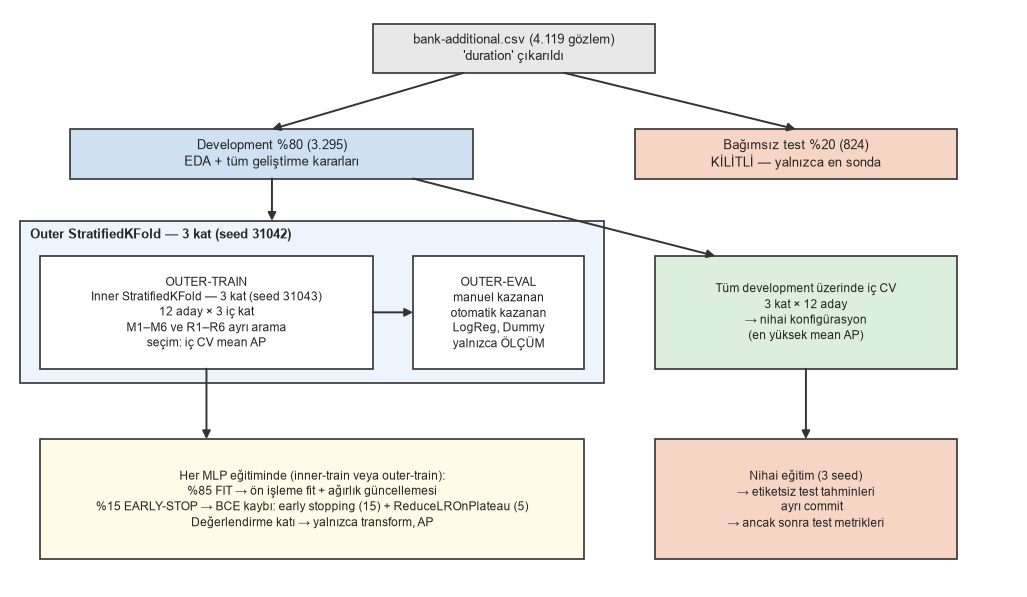

In [14]:
fig, ax = plt.subplots(figsize=(13, 7.5)); ax.axis("off")
def box(x, y, w, h, text, fc, fs=9, bold=False):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=fc, ec="#333", lw=1.2, zorder=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, zorder=3,
            weight="bold" if bold else "normal", linespacing=1.4)
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), zorder=2,
                arrowprops=dict(arrowstyle="-|>", lw=1.4, color="#333", shrinkA=0, shrinkB=0))
box(0.36, 0.91, 0.28, 0.07, "bank-additional.csv (4.119 gözlem)\n'duration' çıkarıldı", "#e8e8e8")
box(0.06, 0.76, 0.40, 0.07, "Development %80 (3.295)\nEDA + tüm geliştirme kararları", "#cfe0f3")
box(0.62, 0.76, 0.32, 0.07, "Bağımsız test %20 (824)\nKİLİTLİ — yalnızca en sonda", "#f6d5c4")
arrow(0.45, 0.91, 0.26, 0.83); arrow(0.55, 0.91, 0.78, 0.83)
# Outer CV bloğu
box(0.01, 0.47, 0.58, 0.23, "", "#eef4fb")
ax.text(0.02, 0.675, "Outer StratifiedKFold — 3 kat (seed 31042)", fontsize=9.5, weight="bold", zorder=3)
box(0.03, 0.49, 0.33, 0.16, "OUTER-TRAIN\nInner StratifiedKFold — 3 kat (seed 31043)\n12 aday × 3 iç kat\nM1–M6 ve R1–R6 ayrı arama\nseçim: iç CV mean AP", "#ffffff", fs=8.5)
box(0.40, 0.49, 0.17, 0.16, "OUTER-EVAL\nmanuel kazanan\notomatik kazanan\nLogReg, Dummy\nyalnızca ÖLÇÜM", "#ffffff", fs=8.5)
arrow(0.36, 0.57, 0.40, 0.57)
arrow(0.26, 0.76, 0.26, 0.70)
# Bir eğitimin içi
box(0.03, 0.22, 0.54, 0.17, "Her MLP eğitiminde (inner-train veya outer-train):\n%85 FIT → ön işleme fit + ağırlık güncellemesi\n%15 EARLY-STOP → BCE kaybı: early stopping (15) + ReduceLROnPlateau (5)\nDeğerlendirme katı → yalnızca transform, AP", "#fffbe6", fs=8.5)
arrow(0.195, 0.49, 0.195, 0.39)
# Nihai seçim ve test
box(0.64, 0.49, 0.30, 0.16, "Tüm development üzerinde iç CV\n3 kat × 12 aday\n→ nihai konfigürasyon\n(en yüksek mean AP)", "#dcefdc", fs=8.5)
arrow(0.40, 0.76, 0.70, 0.65)
box(0.64, 0.22, 0.30, 0.17, "Nihai eğitim (3 seed)\n→ etiketsiz test tahminleri\n    ayrı commit\n→ ancak sonra test metrikleri", "#f6d5c4", fs=8.5)
arrow(0.79, 0.49, 0.79, 0.39)
ax.set_xlim(0, 1); ax.set_ylim(0.18, 1.0)
savefig("flow_nested_cv"); plt.show()

### Şekil 4 — Eğitim ve iç early-stop doğrulama kaybı; epoch bazlı öğrenme oranı (dış kat 1, iç kat 1)

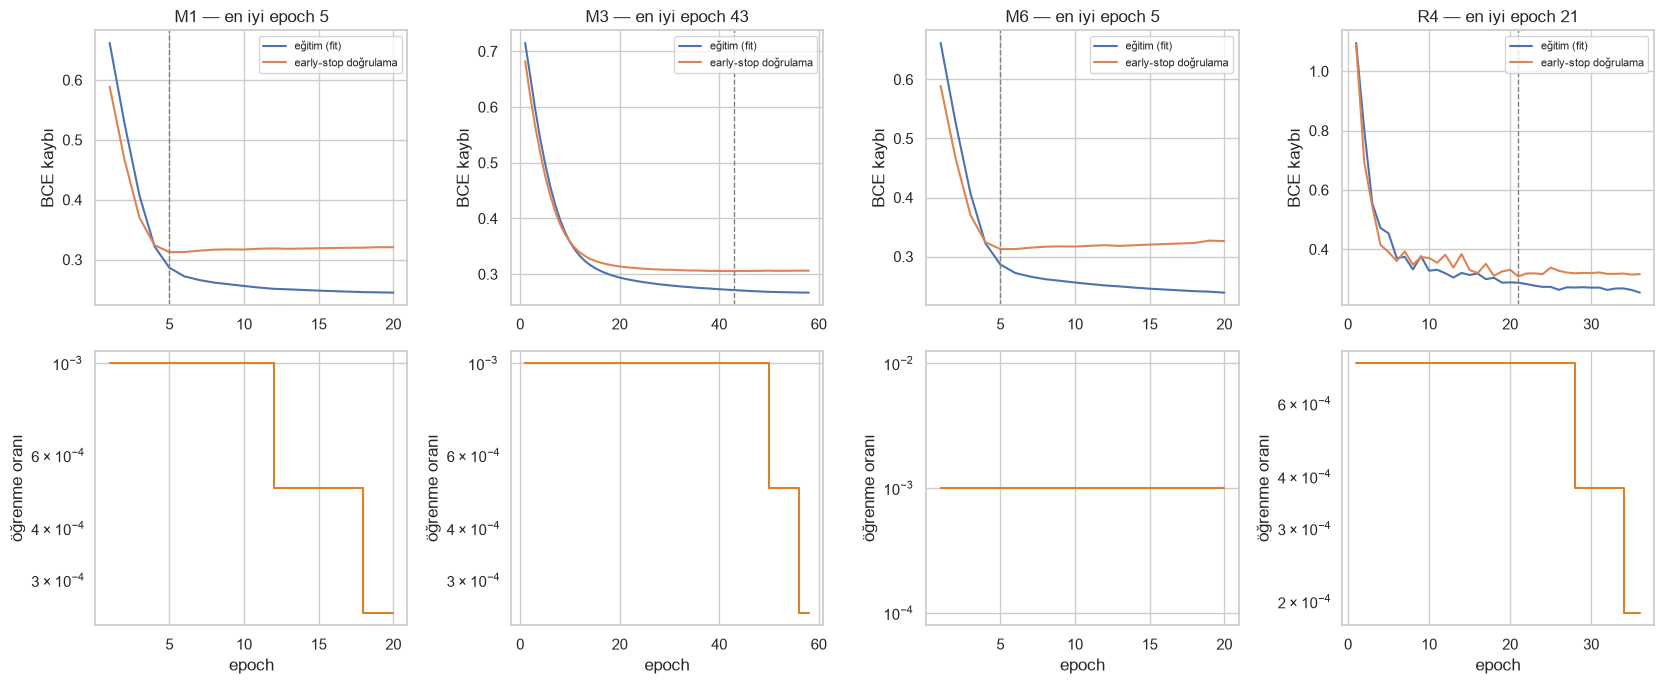

In [15]:
show = ["M1", "M3", "M6", dev_sel["random_best"]]
fig, axes = plt.subplots(2, len(show), figsize=(4.2 * len(show), 7), sharex=False)
for j, c in enumerate(show):
    h = hist[(hist.stage == "inner") & (hist.outer_fold == 1) & (hist.inner_fold == 1) & (hist.code == c)]
    best = h.loc[h.val_loss.idxmin(), "epoch"]
    axes[0, j].plot(h.epoch, h.train_loss, label="eğitim (fit)")
    axes[0, j].plot(h.epoch, h.val_loss, label="early-stop doğrulama")
    axes[0, j].axvline(best, ls="--", c="gray", lw=1); axes[0, j].set_title(f"{c} — en iyi epoch {best}")
    axes[0, j].set_ylabel("BCE kaybı"); axes[0, j].legend(fontsize=8)
    axes[1, j].step(h.epoch, h.lr, where="post", c="#d9822b"); axes[1, j].set_yscale("log")
    axes[1, j].set_xlabel("epoch"); axes[1, j].set_ylabel("öğrenme oranı")
plt.tight_layout(); savefig("training_curves"); plt.show()

### Şekil 5 — Manuel ve otomatik adayların iç CV AP karşılaştırması

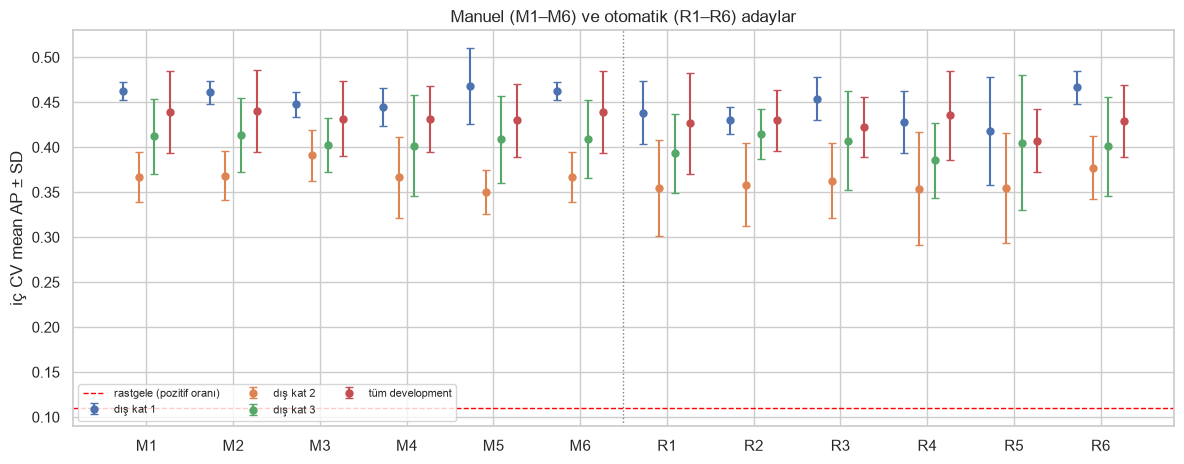

In [16]:
both = pd.concat([manual.assign(search="Manuel"), rand.assign(search="Otomatik")])
order = list(cands["manual"]) + list(cands["random"])
scopes = ["outer_1", "outer_2", "outer_3", "development"]
fig, ax = plt.subplots(figsize=(12, 4.8))
offs = np.linspace(-0.27, 0.27, len(scopes))
for k, sc in enumerate(scopes):
    d = both[both.scope == sc].set_index("code").reindex(order)
    ax.errorbar(np.arange(len(order)) + offs[k], d.mean_AP, yerr=d.sd_AP, fmt="o", capsize=3, ms=5,
                label=sc.replace("outer_", "dış kat ").replace("development", "tüm development"))
ax.axvline(5.5, c="gray", lw=1, ls=":")
ax.axhline(df_dev[TARGET].mean(), c="red", lw=1, ls="--", label="rastgele (pozitif oranı)")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
ax.set_ylabel("iç CV mean AP ± SD"); ax.set_title("Manuel (M1–M6) ve otomatik (R1–R6) adaylar")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); savefig("search_comparison"); plt.show()

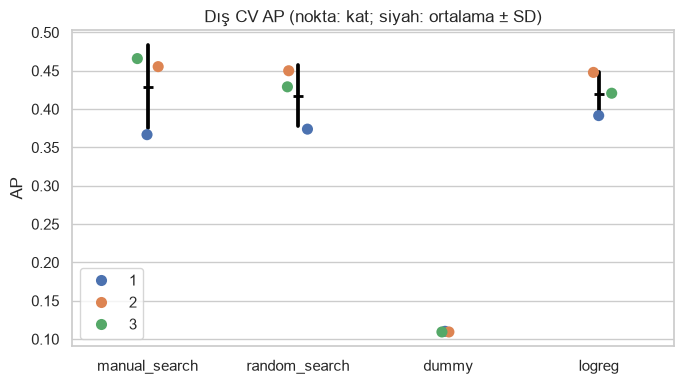

In [17]:
# Dış CV: yöntemlerin AP karşılaştırması (kat bazlı noktalar)
fig, ax = plt.subplots(figsize=(7, 4))
sns.stripplot(data=outer, x="method", y="AP", hue="outer_fold", s=8, ax=ax, palette="deep")
sns.pointplot(data=outer, x="method", y="AP", errorbar="sd", color="black", markers="_", linestyles="none", ax=ax)
ax.set_title("Dış CV AP (nokta: kat; siyah: ortalama ± SD)"); ax.set_xlabel("")
plt.tight_layout(); savefig("outer_cv_ap"); plt.show()

## 6. Yorum (doldurulacak)

- H1–H4 hipotezlerinin iç CV sonuçlarına göre değerlendirilmesi (M1 vs M2/M3/M4/M5/M6; R adayları).
- Dış katlarda seçilen adayların tutarlılığı; manuel ve otomatik aramanın dış CV genelleme tahmini; LogReg/Dummy karşılaştırması.
- Nihai seçim: tüm development iç CV — dış sonuçlara bakılarak yapılmamıştır.